# Practical tasks

##### Please explore the datasets and answer the questions below.
##### Here are some guidlines and advices you should consider:
* you can add as many cells as is comfortable for you for each answer
* some questions require your explanation. Add a cell and choose a markdown option in the menu 
* when you are making plots, please add labels to the axes

In [53]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

import seaborn as sns
from sklearn.cluster import KMeans

# Clustering tasks

The problem that we are going to solve in this section is to segment customers into different groups based on their shopping trends.

The dataset for this problem `shopping-data.csv`

#### 1. Load the data and preview

In [54]:
customer_data = pd.read_csv('shopping-data.csv')

In [55]:
customer_data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [56]:
customer_data.describe()

,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


#### 2. Plot scatter plot for annual income and spending score which will be used for clustering in the next steps

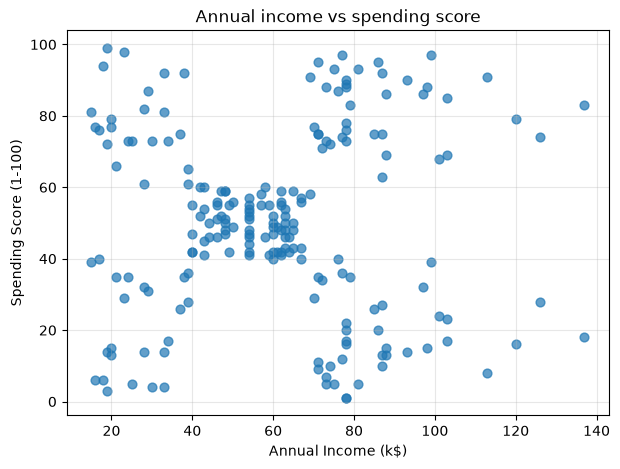

In [57]:
plt.figure(figsize=(7, 5))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'], s=40, alpha=0.7)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Annual income vs spending score')
plt.grid(True, alpha=0.3)
plt.show()

#### 3. Normalize the data

In [58]:
X_shop = customer_data[['Annual Income (k$)', 'Spending Score (1-100)']]
scaler_shop = StandardScaler()
X_shop_scaled = scaler_shop.fit_transform(X_shop)
print(X_shop_scaled[:5])
print('mean:', X_shop_scaled.mean(axis=0).round(3), ' std:', X_shop_scaled.std(axis=0).round(3))

[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]
mean: [-0. -0.]  std: [1. 1.]


#### 4. Use Elbow method to decide number of clusters

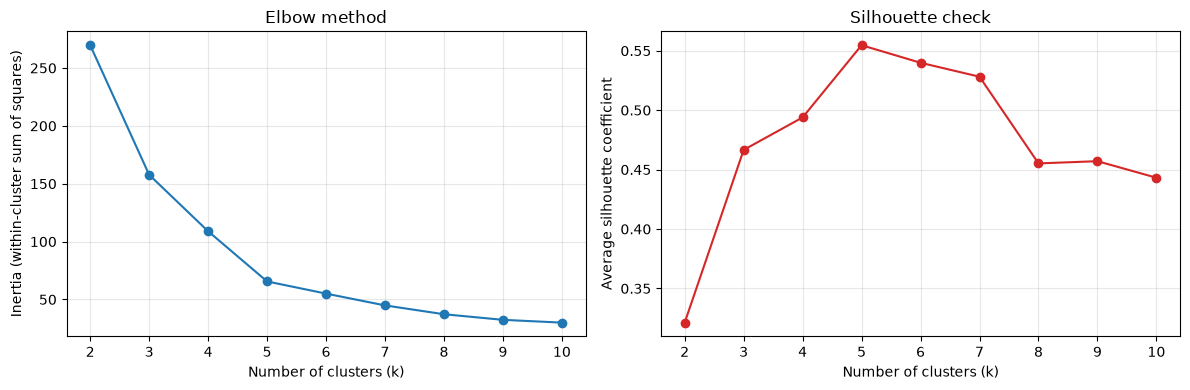

{2: np.float64(0.321), 3: np.float64(0.467), 4: np.float64(0.494), 5: np.float64(0.555), 6: np.float64(0.54), 7: np.float64(0.528), 8: np.float64(0.455), 9: np.float64(0.457), 10: np.float64(0.443)}


In [59]:
from sklearn.metrics import silhouette_score

inertias, sils = [], []
ks = range(2, 11)
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42)
    km.fit(X_shop_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_shop_scaled, km.labels_))

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(ks, inertias, 'o-')
ax[0].set_xlabel('Number of clusters (k)')
ax[0].set_ylabel('Inertia (within-cluster sum of squares)')
ax[0].set_title('Elbow method')
ax[0].grid(True, alpha=0.3)
ax[1].plot(ks, sils, 'o-', color='tab:red')
ax[1].set_xlabel('Number of clusters (k)')
ax[1].set_ylabel('Average silhouette coefficient')
ax[1].set_title('Silhouette check')
ax[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
print(dict(zip(ks, np.round(sils, 3))))

#### 5. Perform Clustering using KMeans

In [60]:
# kmeans with 5 clusters (from the elbow plot)
kmeans_shop = KMeans(n_clusters=5, init='k-means++', n_init=10, random_state=42)
shop_km_labels = kmeans_shop.fit_predict(X_shop_scaled)

# save the cluster number for each customer
customer_data['KMeans_cluster'] = shop_km_labels
print(customer_data['KMeans_cluster'].value_counts().sort_index())

KMeans_cluster
0    81
1    39
2    22
3    35
4    23
Name: count, dtype: int64


#### 6. Plot scatter plot and color code in clustered groups

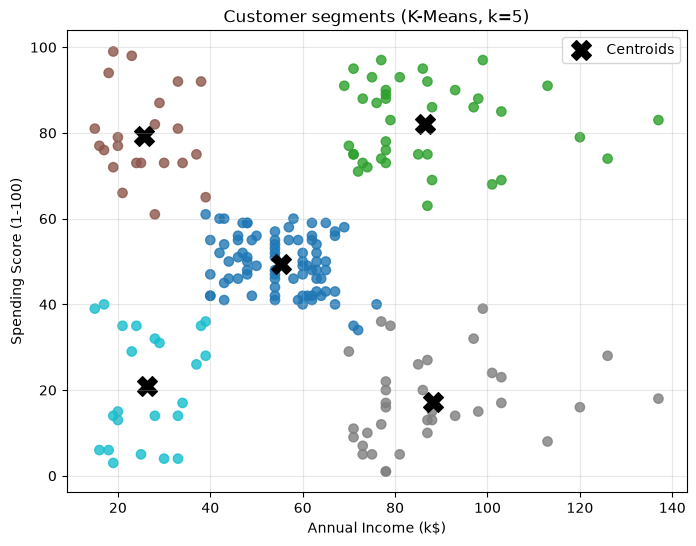

In [61]:
plt.figure(figsize=(8, 6))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'],
            c=shop_km_labels, cmap='tab10', s=45, alpha=0.8)

# centroids are in scaled units, so convert them back to normal income/score
centers = scaler_shop.inverse_transform(kmeans_shop.cluster_centers_)
plt.scatter(centers[:, 0], centers[:, 1], c='black', marker='X', s=200, label='Centroids')

plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer segments (K-Means, k=5)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

#### 7. Plot dendrogram to decide number of clusters for Hierarchical Clustering. <br> Explain (free text in a markdown cell) what is the optimal number of clusters and why

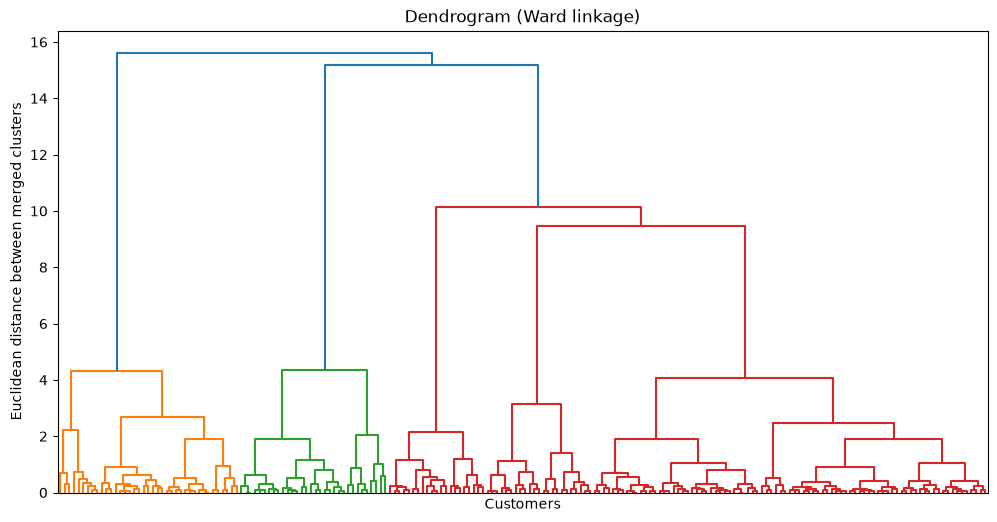

6 clusters left after merge at 4.31
5 clusters left after merge at 4.35
4 clusters left after merge at 9.45
3 clusters left after merge at 10.14
2 clusters left after merge at 15.19
1 clusters left after merge at 15.62


In [62]:
import scipy.cluster.hierarchy as shc


plt.figure(figsize=(12, 6))
shc.dendrogram(shc.linkage(X_shop_scaled, method='ward'))
plt.title('Dendrogram (Ward linkage)')
plt.xlabel('Customers')
plt.ylabel('Euclidean distance between merged clusters')
plt.xticks([])  # 200 labels would be unreadable
plt.show()

# distance of the last 6 merges (3rd column of the linkage matrix)
Z = shc.linkage(X_shop_scaled, method='ward')
last_merges = Z[-6:, 2]

# after each merge, this many clusters are left
for clusters_left, dist in zip(range(6, 0, -1), last_merges):
    print(f'{clusters_left} clusters left after merge at {dist:.2f}')

**OBSERVATION:** The optimal number of clusters is 5. On the dendrogram I look for the longest vertical line that no horizontal line crosses and cut there. The last merges happened around 4.35,9.45,10.14 and 15.19 and the biggest empty gap is between 4.35 to 9.45.A cut in that gap gives 5 clusters .5 also matches the elbow and silhouette results from K-Means.

#### 8. Do clustering using Hierarchical Clustering

In [63]:
from sklearn.cluster import AgglomerativeClustering

# 5 clusters, same ward linkage as the dendrogram
hc_shop = AgglomerativeClustering(n_clusters=5, metric='euclidean', linkage='ward')
shop_hc_labels = hc_shop.fit_predict(X_shop_scaled)

# save the cluster number for each customer
customer_data['HC_cluster'] = shop_hc_labels
print(customer_data['HC_cluster'].value_counts().sort_index())

HC_cluster
0    32
1    39
2    85
3    21
4    23
Name: count, dtype: int64


#### 9. Plot scatter plot and color code in clustered groups

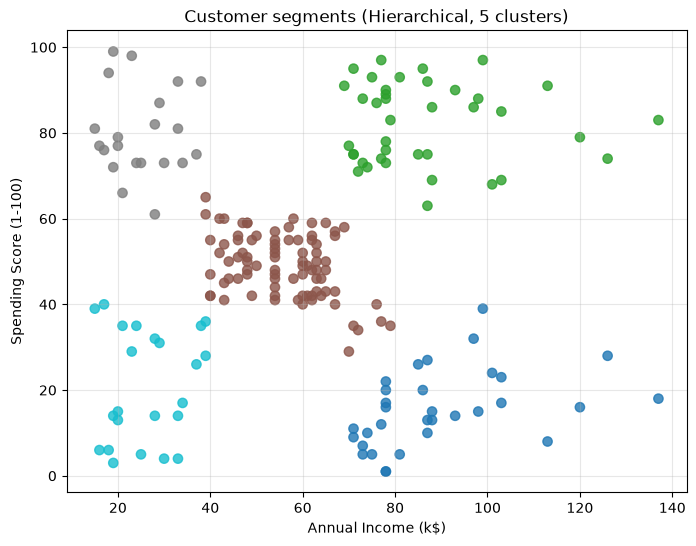

Agreement between K-Means and hierarchical: 0.942


In [64]:
plt.figure(figsize=(8, 6))
plt.scatter(customer_data['Annual Income (k$)'], customer_data['Spending Score (1-100)'],
            c=shop_hc_labels, cmap='tab10', s=45, alpha=0.8)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Customer segments (Hierarchical, 5 clusters)')
plt.grid(True, alpha=0.3)
plt.show()

# how similar are the K-Means and hierarchical results (1 = identical)
from sklearn.metrics import adjusted_rand_score
print('Agreement between K-Means and hierarchical:', round(adjusted_rand_score(shop_km_labels, shop_hc_labels), 3))

####  10. Do KMeans and DBSCAN clustering on this data

In [65]:
from sklearn.datasets import make_moons
#moons_X: Data, moon_y: Labels
moons_X, moon_y = make_moons(n_samples=2000)

Text(0.5, 1.0, 'Half Moons')

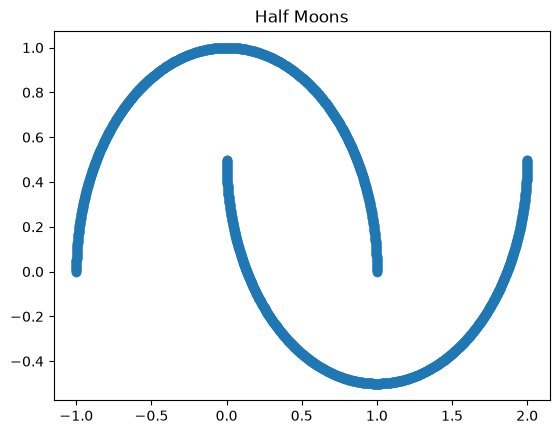

In [66]:
plt.scatter(moons_X[:,0],moons_X[:,1])
plt.title('Half Moons')

#### Using KMeans (do clustering and plot results (each cluster in own color))

In [67]:
# only 2 clusters because we can see 2 moons
kmeans_moons = KMeans(n_clusters=2, n_init=10, random_state=42)
moons_km_labels = kmeans_moons.fit_predict(moons_X)

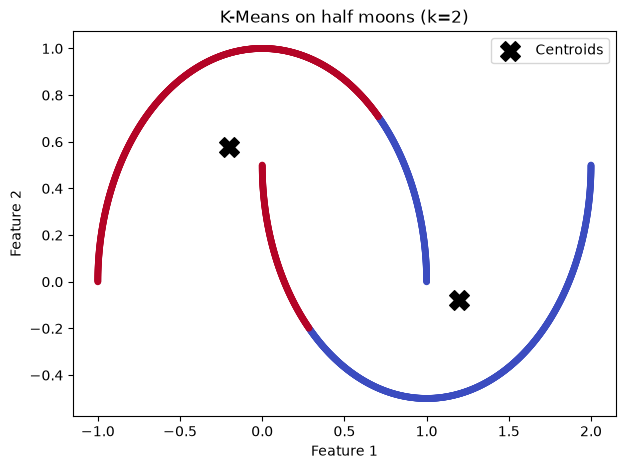

In [68]:
plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=moons_km_labels, cmap='coolwarm', s=15)
plt.scatter(*kmeans_moons.cluster_centers_.T, c='black', marker='X', s=200, label='Centroids')
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title('K-Means on half moons (k=2)')
plt.legend()
plt.show()

#### 11. Using DBSCAN do clustering and plot results (each cluster in own color). Find the most suitable eps and minimal samples number

In [69]:
from sklearn.cluster import DBSCAN

# try different eps and min_samples and see what we get
# true labels (moon_y) are only used to check the result, dbscan doesn't see them
rows = []
for eps in [0.05, 0.1, 0.15, 0.2, 0.3, 0.5]:
    for ms in [3, 5, 10, 20]:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(moons_X)
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)  # -1 is noise, not a cluster
        n_noise = (labels == -1).sum()
        rows.append((eps, ms, n_clusters, n_noise, round(adjusted_rand_score(moon_y, labels), 3)))

grid = pd.DataFrame(rows, columns=['eps', 'min_samples', 'n_clusters', 'n_noise', 'ARI_vs_true'])
print(grid.to_string(index=False))

 eps  min_samples  n_clusters  n_noise  ARI_vs_true
0.05            3           2        0          1.0
0.05            5           2        0          1.0
0.05           10           2        0          1.0
0.05           20           2        0          1.0
0.10            3           2        0          1.0
0.10            5           2        0          1.0
0.10           10           2        0          1.0
0.10           20           2        0          1.0
0.15            3           2        0          1.0
0.15            5           2        0          1.0
0.15           10           2        0          1.0
0.15           20           2        0          1.0
0.20            3           2        0          1.0
0.20            5           2        0          1.0
0.20           10           2        0          1.0
0.20           20           2        0          1.0
0.30            3           2        0          1.0
0.30            5           2        0          1.0
0.30        

clusters found: 2
noise points: 0


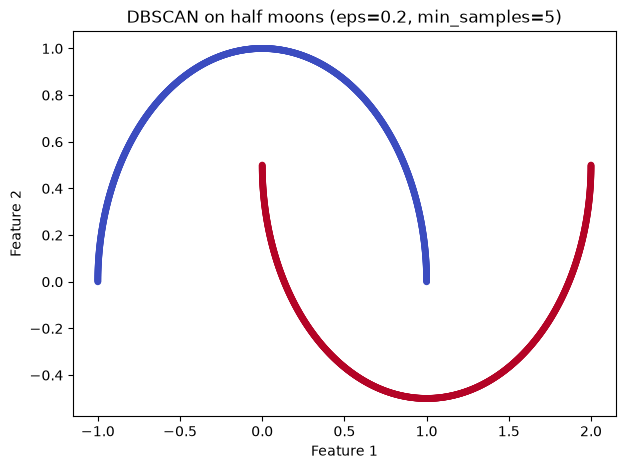

In [70]:
eps_best, ms_best = 0.2, 5
dbscan_moons = DBSCAN(eps=eps_best, min_samples=ms_best)
moons_db_labels = dbscan_moons.fit_predict(moons_X)

print('clusters found:', len(set(moons_db_labels)) - (1 if -1 in moons_db_labels else 0))
print('noise points:', (moons_db_labels == -1).sum())

plt.figure(figsize=(7, 5))
plt.scatter(moons_X[:, 0], moons_X[:, 1], c=moons_db_labels, cmap='coolwarm', s=15)
plt.xlabel('Feature 1')
plt.ylabel('Feature 2')
plt.title(f'DBSCAN on half moons (eps={eps_best}, min_samples={ms_best})')
plt.show()

#### 12. Compare the results of K-means and DBSCAN clustering
Explain why one or another is prefferable for such dataset, and differences if any.

In [71]:
# how close is each result to the true moons (1 = perfect)
print('K-Means ARI:', round(adjusted_rand_score(moon_y, moons_km_labels), 3))
print('DBSCAN ARI:', round(adjusted_rand_score(moon_y, moons_db_labels), 3))

K-Means ARI: 0.254
DBSCAN ARI: 1.0


**OBSERVATION:** DBSCAN has an ARI of 1, while K-Means has 0.25. K-Means assigns each point to the nearest centroid, so it expects round clusters, therefore it splits each moon in half and mixes them. DBSCAN doesn't care about shape. It connects points that have enough neighbours within eps, so it finds both moons correctly.

### Perform PCA on penguins :)
###### This section uses kaggle dataset (https://www.kaggle.com/datasets/youssefaboelwafa/clustering-penguins-species/data)
###### The tasks below include data analysis, data preprocessing, PCA, and application of classification to predict the target

#### 13. Describe the data. Do any additional exporations as you feel

In [72]:
# Dataset
penguins = pd.read_csv('penguins.csv')
penguins.head()

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,NaN,NaN,NaN,NaN,NaN
4,36.7,19.3,193.0,3450.0,FEMALE


In [73]:
# size of the data
print('Shape (rows, columns):', penguins.shape)
print()

# column types and how many values are not missing
penguins.info()
print()

# basic stats for the number columns
penguins.describe()

Shape (rows, columns): (344, 5)

<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   culmen_length_mm   342 non-null    float64
 1   culmen_depth_mm    342 non-null    float64
 2   flipper_length_mm  342 non-null    float64
 3   body_mass_g        342 non-null    float64
 4   sex                335 non-null    str    
dtypes: float64(4), str(1)
memory usage: 13.6 KB



,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g
count,342.000000,342.000000,342.000000,342.000000
mean,43.921930,17.151170,214.014620,4201.754386
std,5.459584,1.974793,260.558057,801.954536
min,32.100000,13.100000,-132.000000,2700.000000
25%,39.225000,15.600000,190.000000,3550.000000
50%,44.450000,17.300000,197.000000,4050.000000
75%,48.500000,18.700000,213.750000,4750.000000
max,59.600000,21.500000,5000.000000,6300.000000


#### Based on dataframe describe, in own words explain any abnormal characteristics 

**OBSERVATION:** 
- The flipper length column has two impossible values such as the  minimum is -132mm, which cant be a real flipper length and the maximum is 5000mm (5 meter).Because of these two values the mean 214 and std 260 are way off compared to quartiles (190-214), therefore the stat of this column cannot be considered as they are. 

- The count of number columns are 342, but the file has 344 rows, which means 2 rows have no measurements at all.

- describe() doesn't show the sex column, but info() shows only 335 values in it, so some sex values are missing too.

- The other columns (body_mass_g, culmen_length_mm and culmen_depth_mm) look normal.

#### 14. Explore corrupted data

In [74]:
# missing values in each column
print(penguins.isna().sum())
print()

# rows that have at least one missing value
missing_rows = penguins[penguins.isna().any(axis=1)]
print('Rows with missing values:', missing_rows.shape)
missing_rows

culmen_length_mm     2
culmen_depth_mm      2
flipper_length_mm    2
body_mass_g          2
sex                  9
dtype: int64

Rows with missing values: (9, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
3,NaN,NaN,NaN,NaN,NaN
8,34.1,18.1,193.0,3475.0,NaN
10,37.8,17.1,186.0,3300.0,NaN
11,37.8,17.3,180.0,3700.0,NaN
47,37.5,18.9,179.0,2975.0,NaN
246,44.5,14.3,216.0,4100.0,NaN
286,46.2,14.4,214.0,4650.0,NaN
324,47.3,13.8,216.0,4725.0,NaN
339,NaN,NaN,NaN,NaN,NaN


In [75]:
# all values in sex, including the missing ones
print(penguins['sex'].value_counts(dropna=False))
print()

# the strange "." value
penguins[penguins['sex'] == '.']

sex
MALE      169
FEMALE    165
NaN         9
.           1
Name: count, dtype: int64



,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
336,44.5,15.7,217.0,4875.0,.


In [76]:
# flipper lengths that are impossible (negative or way too big)
anomalies = penguins[(penguins['flipper_length_mm'] < 0) | (penguins['flipper_length_mm'] > 300)]
print('Anomalous rows:', anomalies.shape)
anomalies

Anomalous rows: (2, 5)


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
9,42.0,20.2,5000.0,4250.0,MALE
14,34.6,21.1,-132.0,4400.0,MALE


#### 15. Based on observations above, prepare the data for PCA. Only valid rows should be present. <br> Preview dataframe, show its size

In [77]:
# the 4 number columns we use for PCA
num_cols = ['culmen_length_mm', 'culmen_depth_mm', 'flipper_length_mm', 'body_mass_g']

# keep only valid rows: no missing numbers, normal flipper length, and sex is MALE or FEMALE
valid_mask = (
    penguins[num_cols].notna().all(axis=1)
    & penguins['flipper_length_mm'].between(1, 300)
    & penguins['sex'].isin(['MALE', 'FEMALE'])
)
penguins_clean = penguins[valid_mask].reset_index(drop=True)

print('Before:', penguins.shape, ' After:', penguins_clean.shape)
print(penguins_clean['sex'].value_counts())
penguins_clean.head()

Before: (344, 5)  After: (332, 5)
sex
MALE      167
FEMALE    165
Name: count, dtype: int64


,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex
0,39.1,18.7,181.0,3750.0,MALE
1,39.5,17.4,186.0,3800.0,FEMALE
2,40.3,18.0,195.0,3250.0,FEMALE
3,36.7,19.3,193.0,3450.0,FEMALE
4,39.3,20.6,190.0,3650.0,MALE


In [78]:
# scale the 4 number columns (mean 0, std 1)
scaler_peng = StandardScaler()
X_penguins = scaler_peng.fit_transform(penguins_clean[num_cols])
print(X_penguins.shape)

(332, 4)


In [79]:
# the thing we want to predict later
y_penguins = penguins_clean['sex']
y_penguins.value_counts()

sex
MALE      167
FEMALE    165
Name: count, dtype: int64

#### 15. Explain the chosen null values handling strategy, how it affects the dataset (pros/cons)

**Answer:**
I removed the rows that can't be used. That was 2 rows where every measurement is missing, 2 rows with impossible flipper lengths (-132 and 5000), and 8 rows where sex is missing or is a ".". The data went from 344 rows to 332. The 8 rows that have good measurements but no sex were not thrown away for good. I kept them aside to predict their sex in task 20.

**Pros**
- It is simple and nothing is made up, so PCA and the model only see real measurements.
- The two impossible flipper values would have messed up the scaling and the components (one value of 5000 is enough to dominate the variance), so dropping them is safer than keeping them.
- We lost only about 3.5% of the data and the sex classes stay balanced (167 male, 165 female).

**Cons**
- We lose some information. For the two rows with bad flipper values, the other three measurements were probably fine, so we could have replaced the flipper value (for example with the median) and kept the rows.
- Filling in the missing sex would not be a good idea, because sex is what we want to predict. Filling it with the most common value would add fake labels and bias the model.
- Dropping rows only works well if the missing values are random. With 12 rows out of 344 the risk is small here.

#### 16. Perform PCA with 2 components. Plot the results 

Explained variance ratio: [0.687 0.196]
Total: 0.884


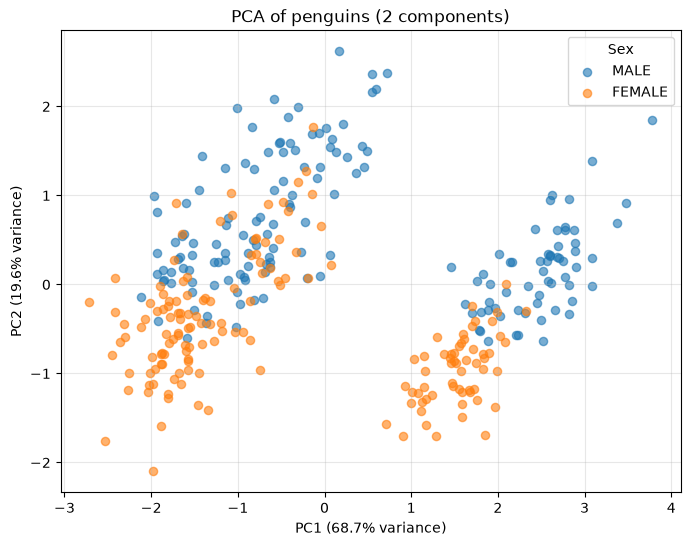

In [80]:
# reduce the 4 scaled features to 2 components
pca_peng = PCA(n_components=2)
X_penguins_pca = pca_peng.fit_transform(X_penguins)
print('Explained variance ratio:', pca_peng.explained_variance_ratio_.round(3))
print('Total:', round(pca_peng.explained_variance_ratio_.sum(), 3))

# plot, colored by sex
plt.figure(figsize=(8, 6))
for sex, color in [('MALE', 'tab:blue'), ('FEMALE', 'tab:orange')]:
    m = (y_penguins == sex).values
    plt.scatter(X_penguins_pca[m, 0], X_penguins_pca[m, 1], label=sex, color=color, alpha=0.6, s=35)
plt.xlabel(f'PC1 ({pca_peng.explained_variance_ratio_[0]:.1%} variance)')
plt.ylabel(f'PC2 ({pca_peng.explained_variance_ratio_[1]:.1%} variance)')
plt.title('PCA of penguins (2 components)')
plt.legend(title='Sex')
plt.grid(True, alpha=0.3)
plt.show()

#### 17. Display scree plots to determine the optimal number of components and cumulative explained variance

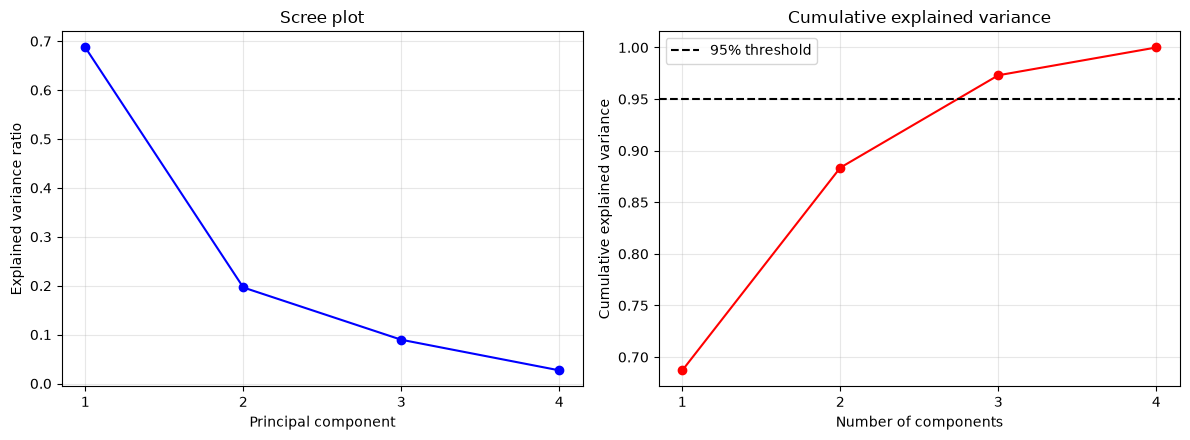

PC1: 68.71%  (cumulative 68.71%)
PC2: 19.64%  (cumulative 88.35%)
PC3: 8.95%  (cumulative 97.31%)
PC4: 2.69%  (cumulative 100.00%)


In [81]:
# Apply PCA with all components
pca_full_peng = PCA().fit(X_penguins)
evr = pca_full_peng.explained_variance_ratio_
comps = range(1, len(evr) + 1)

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

# scree plot: variance of each component
ax[0].plot(comps, evr, 'bo-')
ax[0].set_xlabel('Principal component')
ax[0].set_ylabel('Explained variance ratio')
ax[0].set_title('Scree plot')
ax[0].set_xticks(list(comps))
ax[0].grid(True, alpha=0.3)

# cumulative variance, with a 95% line
ax[1].plot(comps, np.cumsum(evr), 'ro-')
ax[1].axhline(0.95, color='k', linestyle='--', label='95% threshold')
ax[1].set_xlabel('Number of components')
ax[1].set_ylabel('Cumulative explained variance')
ax[1].set_title('Cumulative explained variance')
ax[1].set_xticks(list(comps))
ax[1].legend()
ax[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

for i, (v, c) in enumerate(zip(evr, np.cumsum(evr)), 1):
    print(f'PC{i}: {v:.2%}  (cumulative {c:.2%})')

**OBSERVATION:** PC1 explains 68.71% of the variance and PC2 19.64%, so 2 components keep 88.35%. The scree plot bends after PC2, so 2 components is a good choice. If we want to keep more than 95% of the variance, we need 3 components (97.31%).

#### 18. Calculate (show in numbers) and display component loadings

In [82]:
# how much each original feature contributes to each component
loadings = pd.DataFrame(pca_peng.components_.T, columns=['PC1', 'PC2'], index=num_cols)
print(loadings.round(3))

                     PC1    PC2
culmen_length_mm   0.453  0.605
culmen_depth_mm   -0.399  0.793
flipper_length_mm  0.577  0.004
body_mass_g        0.550  0.072


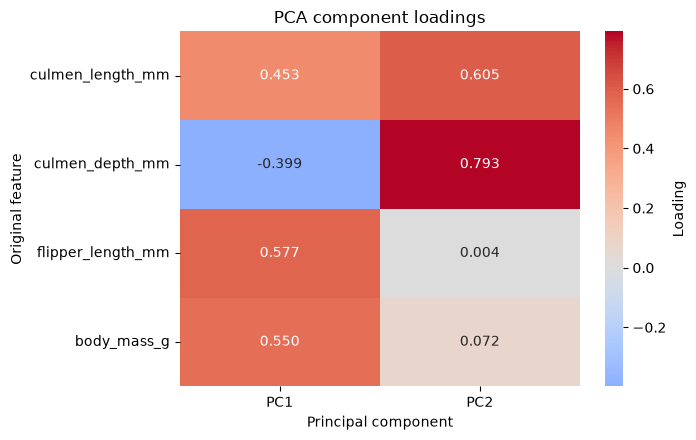

In [83]:
plt.figure(figsize=(7, 4.5))
sns.heatmap(loadings, annot=True, cmap='coolwarm', center=0, fmt='.3f', cbar_kws={'label': 'Loading'})
plt.xlabel('Principal component')
plt.ylabel('Original feature')
plt.title('PCA component loadings')
plt.tight_layout()
plt.show()

**OBSERVATION** 
PC1 is mostly flipper length and body mass, with culmen length close behind. It works like an overall body size. Culmen depth goes the other way (negative), which fits two groups of penguins where the bigger one has shallower culmens.

PC2 is mostly culmen depth and culmen length, and flipper length and mass barely count. This is the axis where males and females separated in the plot.

#### 19. Perform logistic regression (or any other classification algorithm) and evaluate the model

In [84]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# split the PCA data: 70% train, 30% test
# stratify keeps the male/female ratio the same in both parts
X_train, X_test, y_train, y_test = train_test_split(
    X_penguins_pca, y_penguins, test_size=0.3, random_state=101, stratify=y_penguins)

# train and predict
clf = LogisticRegression(max_iter=200)
clf.fit(X_train, y_train)
y_pred = clf.predict(X_test)

# check the results
print('Accuracy (2 PCs):', round(accuracy_score(y_test, y_pred), 3))
print(classification_report(y_test, y_pred))
print('Confusion matrix (rows = true, cols = predicted; FEMALE, MALE):')
print(confusion_matrix(y_test, y_pred, labels=['FEMALE', 'MALE']))

# for comparison: same thing but with all 4 scaled features, no PCA
Xtr, Xte, ytr, yte = train_test_split(X_penguins, y_penguins, test_size=0.3, random_state=101, stratify=y_penguins)
clf_full = LogisticRegression(max_iter=200).fit(Xtr, ytr)
print('Accuracy (all 4 features):', round(accuracy_score(yte, clf_full.predict(Xte)), 3))

Accuracy (2 PCs): 0.8
              precision    recall  f1-score   support

      FEMALE       0.81      0.78      0.80        50
        MALE       0.79      0.82      0.80        50

    accuracy                           0.80       100
   macro avg       0.80      0.80      0.80       100
weighted avg       0.80      0.80      0.80       100

Confusion matrix (rows = true, cols = predicted; FEMALE, MALE):
[[39 11]
 [ 9 41]]
Accuracy (all 4 features): 0.87


#### 20. Train the model on all data points, and determine penguin sex for the data, where it was not originally identified

In [85]:
# rows with good measurements but no valid sex
unknown_mask = (
    penguins[num_cols].notna().all(axis=1)
    & penguins['flipper_length_mm'].between(1, 300)
    & ~penguins['sex'].isin(['MALE', 'FEMALE'])
)
penguins_unknown = penguins[unknown_mask].copy()
print('Rows with unknown sex:', penguins_unknown.shape[0])

# scale with the scaler we already fitted, so the scale matches the training data
X_unknown = scaler_peng.transform(penguins_unknown[num_cols])

Rows with unknown sex: 8


In [86]:
# same pca as before, only transform
X_unknown_pca = pca_peng.transform(X_unknown)
X_unknown_pca

array([[-1.84704765, -0.78643204],
       [-1.74324155, -0.79794856],
       [-1.75745513, -0.68276355],
       [-2.64503787, -0.13303451],
       [ 1.16637536, -1.10806084],
       [ 1.58123213, -0.82997265],
       [ 1.92855926, -0.94355846],
       [ 1.45235945, -0.47128001]])

In [87]:
# train on all 332 clean rows now, no test split
X_train_all = X_penguins_pca
y_train_all = y_penguins

final_clf = LogisticRegression(max_iter=200)
final_clf.fit(X_train_all, y_train_all)
print('Training accuracy:', round(final_clf.score(X_train_all, y_train_all), 3))

Training accuracy: 0.81


In [88]:
# predicted sex, plus the probability of male
penguins_unknown['predicted_sex'] = final_clf.predict(X_unknown_pca)
penguins_unknown['prob_male'] = final_clf.predict_proba(X_unknown_pca)[:, list(final_clf.classes_).index('MALE')].round(3)
penguins_unknown

,culmen_length_mm,culmen_depth_mm,flipper_length_mm,body_mass_g,sex,predicted_sex,prob_male
8,34.1,18.1,193.0,3475.0,NaN,FEMALE,0.073
10,37.8,17.1,186.0,3300.0,NaN,FEMALE,0.075
11,37.8,17.3,180.0,3700.0,NaN,FEMALE,0.095
47,37.5,18.9,179.0,2975.0,NaN,FEMALE,0.200
246,44.5,14.3,216.0,4100.0,NaN,FEMALE,0.130
286,46.2,14.4,214.0,4650.0,NaN,FEMALE,0.257
324,47.3,13.8,216.0,4725.0,NaN,FEMALE,0.237
336,44.5,15.7,217.0,4875.0,.,FEMALE,0.428


**Observation:** The model predicted FEMALE for all 8 penguins with unknown sex. This makes sense because most of them are small, with low body mass and short flippers, and females are smaller than males in this data. 

These predictions are not completely reliable. The model only reached about 80% accuracy on the test data with 2 components (87% with all 4 features), because males and females overlap a lot in the PCA plot. The probabilities are more useful than the labels, especially for the row near 50%.